In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import KFold, GroupKFold
from collections import defaultdict

running mode subject_dependent
running seed 42
fold number: 1 / 2
Fitted RF_SBP
Fitted RF_DBP
fitted both models for feature skew with index 1
fitted both models for feature w with index 2
fitted both models for feature y with index 3
fitted both models for feature z with index 4
fitted both models for feature a with index 5
fitted both models for feature b with index 6
fitted both models for feature c with index 7
fitted both models for feature d with index 8
fitted both models for feature e with index 9
fitted both models for feature bd with index 10
fitted both models for feature scoo with index 11
fitted both models for feature sc with index 12
fitted both models for feature bcda with index 13
fitted both models for feature cw with index 14
fitted both models for feature bcdea with index 15
fitted both models for feature sdoo with index 16
fitted both models for feature cs with index 17
fitted both models for feature tc with index 18
fitted both models for feature ts with index 19


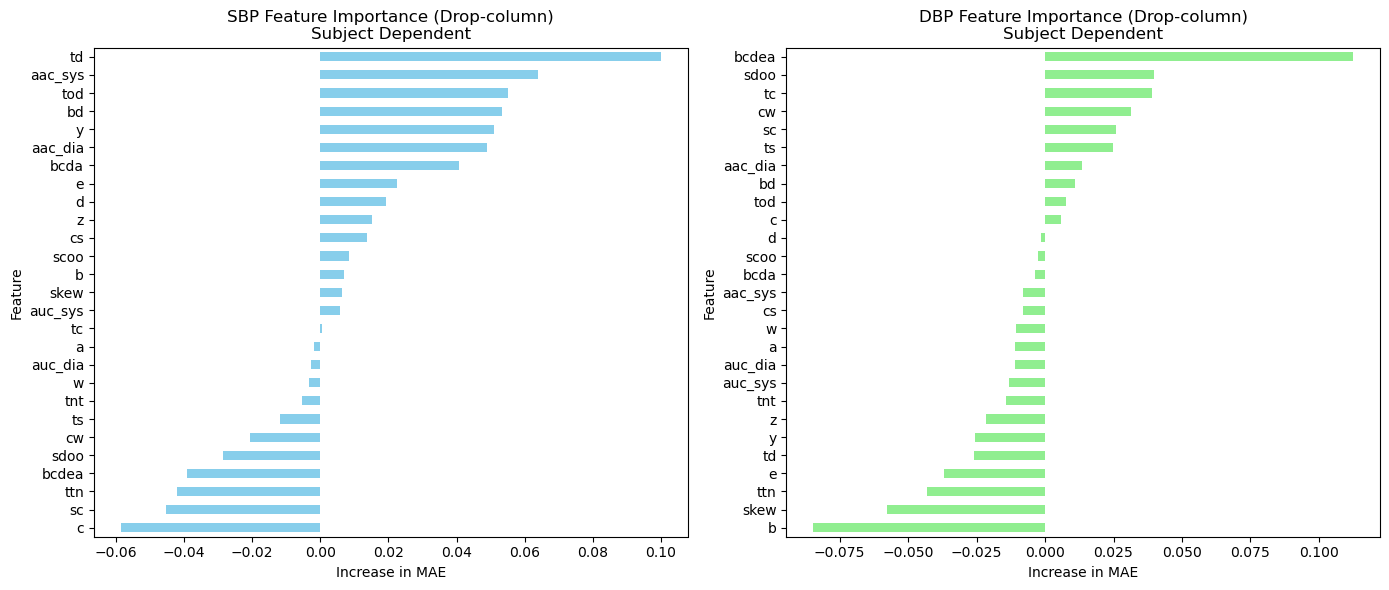

Features covering 66% importance for SBP:
tc       0.164632
skew     0.161521
bcda     0.161333
bcdea    0.133312
dtype: float64
Features covering 66% importance for DBP:
bcdea      0.182112
skew       0.161130
tc         0.078803
auc_dia    0.075043
sdoo       0.060437
e          0.049411
y          0.043728
dtype: float64


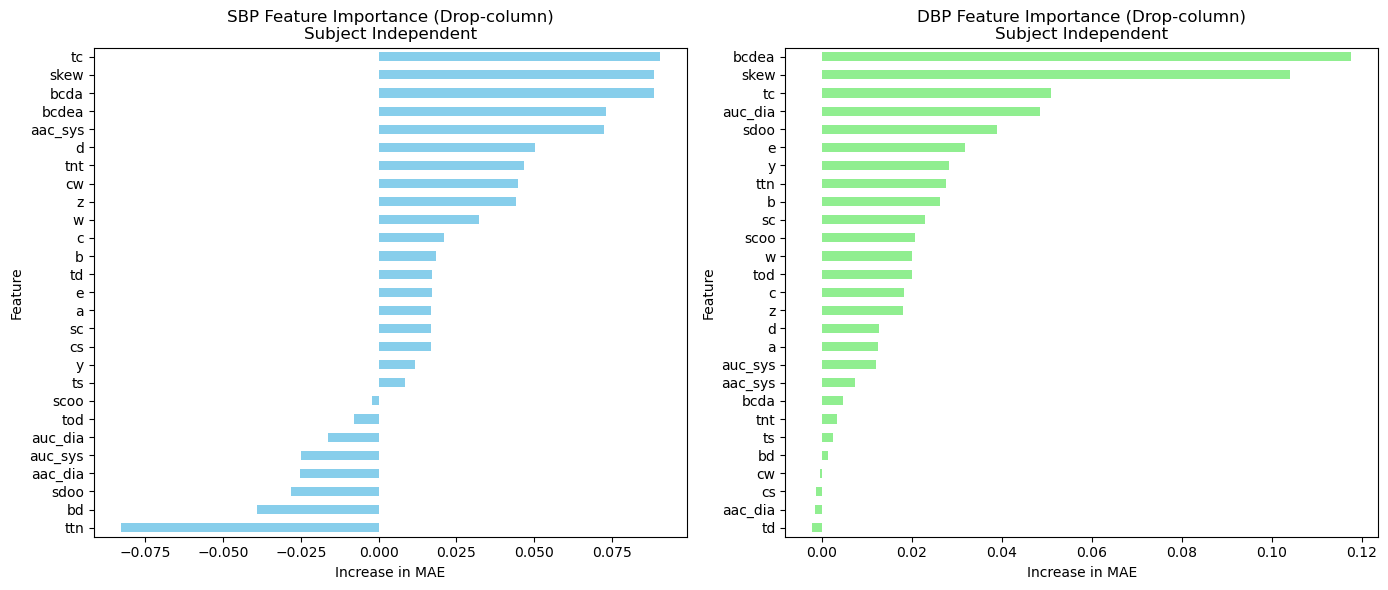

'\nX_train, X_val, y_SBP_train, y_SBP_val = train_test_split(\n    X, y_SBP, test_size=0.2, random_state=42\n)\n\n_, _, y_DBP_train, y_DBP_val = train_test_split(\n    X, y_DBP, test_size=0.2, random_state=42\n)\n\nRF_SBP = RandomForestRegressor(\n    n_estimators=100,\n    random_state=42,\n    n_jobs=-1\n)\n\nRF_DBP = RandomForestRegressor(\n    n_estimators=100,\n    random_state=42,\n    n_jobs=-1\n)\n\n# baseline error: the error of the model trained on all features\nRF_SBP.fit(X_train,y_SBP_train)\nbaseline_error_SBP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val))\nprint(\'Fitted RF_SBP\')\nRF_DBP.fit(X_train,y_DBP_train)\nbaseline_error_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val))\nprint(\'Fitted RF_DBP\')\n\n\nfeature_importances_SBP = {}\nfeature_importances_DBP = {}\ni = 0\nfor f in X_train.columns:\n    X_train_drop = X_train.drop(columns=[f])\n    X_val_drop = X_val.drop(columns=[f])\n\n    RF_SBP.fit(X_train_drop,y_SBP_train)\n    RF_DBP.fit(X_train_

In [ ]:
df = pd.read_csv('PPG_Features_Per_Heartbeat.csv')

y_SBP = df['SBP']
y_DBP = df['DBP']

groups = df['data_ID']

'''
The following features may are either unusable/irrelevant for the RF as they are for segmentaion,
leak too much information or are already encoded morphologically using timings 
- `left_margin`: used for segmentation of the heartbeats
- `right_margin`: used for segmentation of the heartbeats
- `left`: used for segmentation of the heartbeats
- `right`: used for segmentation of the heartbeats
- `sys_idx`: already encoded in ts 
- `dicN_idx`: already encoded in tnt
- `sys_peak`: already encoded in ts 
- `dia_start` already encoded in td/ttn
- `dia_peak`: already encoded in tod
- `mean_sbp`: leak information of the variable to be predicted
- `mean_dbp`: leak information of the variable to be predicted
- `sbp_class`: leak information of the variable to be predicted
- `dbp_class: leak information of the variable to be predicted
'''

exclude_cols = [
    "data_ID", "struct", "SBP", "DBP", "beat_idx",
    "left_margin", "right_margin",
    "left", "right",
    "sys_idx", "dicN_idx", "sys_peak", "dia_start", "dia_peak",
    "mean_sbp", "mean_dbp", 
    "sbp_class", "dbp_class"
]

feature_cols = [c for c in df.columns if c not in exclude_cols]

X = df[feature_cols]

# n_splits = 5
n_splits = 2
# seeds = [42, 0, 12, 39, 4]
seeds = [42]

'''
2 CV strategies: subject leakage (same patients different heartbeats in train and test set) VS none

Subject Dependent: Tests how well features predict within the same patients (with data leakage)
Subject Independent: Tests how well features generalize to new, unseen patients
'''
cv_strategies = {
    "subject_dependent": KFold(n_splits=n_splits),
    "subject_independent": GroupKFold(n_splits=n_splits)
}

results = {}

for mode, splitter in cv_strategies.items():
    print(f'running mode {mode}')

    importance_SBP = defaultdict(list)
    importance_DBP = defaultdict(list)

    for seed in seeds:
        print(f'running seed {seed}')

        # GroupKFold needs groups, KFold does not
        split_args = (
            splitter.split(X, y_SBP, groups)
            if mode == "subject_independent"
            else splitter.split(X)
        )
        '''
        split_args = (
            if mode == "subject_independent":
                splitter.split(X,y_SBP, groups)
            else:
                splitter.split
        )
        '''
        
        for fold, split in enumerate(split_args):
            print(f"fold number: {fold + 1} / {n_splits}")
            train_idx, val_idx = split

            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_SBP_train, y_SBP_val = y_SBP[train_idx], y_SBP[val_idx]
            y_DBP_train, y_DBP_val = y_DBP[train_idx], y_DBP[val_idx]

            RF_SBP = RandomForestRegressor(
                n_estimators=100,
                random_state=seed,
                n_jobs=-1
            )

            RF_DBP = RandomForestRegressor(
                n_estimators=100,
                random_state=seed,
                n_jobs=-1
            )

            # baseline error: the error of the model trained on all features
            RF_SBP.fit(X_train,y_SBP_train)
            baseline_error_SBP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val))
            print('Fitted RF_SBP')

            RF_DBP.fit(X_train,y_DBP_train)
            baseline_error_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val))
            print('Fitted RF_DBP')
            i = 0
            for feature in feature_cols:
                X_train_drop = X_train.drop(columns=feature)
                X_val_drop = X_val.drop(columns=feature)
                RF_SBP_drop = RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)
                RF_DBP_drop = RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)
                RF_SBP_drop.fit(X_train_drop, y_SBP_train)
                RF_DBP_drop.fit(X_train_drop, y_DBP_train)
                

                mae_drop_SBP = mean_absolute_error(
                    y_SBP_val, RF_SBP_drop.predict(X_val_drop)
                )
                mae_drop_DBP = mean_absolute_error(
                    y_DBP_val, RF_DBP_drop.predict(X_val_drop)
                )

                importance_SBP[feature].append(
                    mae_drop_SBP - baseline_error_SBP
                )
                importance_DBP[feature].append(
                    mae_drop_DBP - baseline_error_DBP
                )
                i+=1
                print(f'fitted both models for feature {feature} with index {i}')
    
    # aggregate
    results[mode] = {
        "SBP": pd.Series({
            f: np.mean(v) for f, v in importance_SBP.items()
        }).sort_values(ascending=False),

        "DBP": pd.Series({
            f: np.mean(v) for f, v in importance_DBP.items()
        }).sort_values(ascending=False)
    }

sumSBP = 0
sumDBP = 0
for mode in ["subject_dependent", "subject_independent"]:

    sbp_importance = results[mode]["SBP"]
    sbp_norm = sbp_importance / sbp_importance.sum()
    sumSBP += sbp_norm

    dbp_importance = results[mode]["DBP"]
    dbp_norm = dbp_importance / dbp_importance.sum()
    sumDBP += dbp_norm

    sbp_sorted = sbp_norm.sort_values(ascending=False)
    sbp_cum = sbp_sorted.cumsum()

    # Get features until cumulative importance exceeds 66%
    threshold_idx_sbp = (sbp_cum <= 0.66).sum()
    if threshold_idx_sbp == 0:
        threshold_idx_sbp = 1  # Include at least one feature
    top_features_sbp = sbp_sorted.iloc[:threshold_idx_sbp]
    print("Features covering 66% importance for SBP:")
    print(top_features_sbp)

    dbp_sorted = dbp_norm.sort_values(ascending=False)
    dbp_cum = dbp_sorted.cumsum()

    # top_features_dbp = dbp_sorted[dbp_cum <= 0.66]
    threshold_idx_dbp = (dbp_cum <= 0.66).sum()
    if threshold_idx_dbp == 0:
        threshold_idx_dbp = 1  # Include at least one feature
    top_features_dbp = dbp_sorted.iloc[:threshold_idx_dbp]
    print("Features covering 66% importance for DBP:")
    print(top_features_dbp)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    sbp_importance.sort_values(ascending=True).plot.barh(
        ax=ax[0], color="skyblue"
    )
    ax[0].set_title(f"SBP Feature Importance (Drop-column)\n{mode.replace('_', ' ').title()}")
    ax[0].set_xlabel("Increase in MAE")
    ax[0].set_ylabel("Feature")

    dbp_importance.sort_values(ascending=True).plot.barh(
        ax=ax[1], color="lightgreen"
    )
    ax[1].set_title(f"DBP Feature Importance (Drop-column)\n{mode.replace('_', ' ').title()}")
    ax[1].set_xlabel("Increase in MAE")
    ax[1].set_ylabel("Feature")

    plt.tight_layout()
    plt.savefig(
        f"feature_importance_drop_column_{mode}.png",
        dpi=300
    )
    plt.show()






'''
X_train, X_val, y_SBP_train, y_SBP_val = train_test_split(
    X, y_SBP, test_size=0.2, random_state=42
)

_, _, y_DBP_train, y_DBP_val = train_test_split(
    X, y_DBP, test_size=0.2, random_state=42
)

RF_SBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

RF_DBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# baseline error: the error of the model trained on all features
RF_SBP.fit(X_train,y_SBP_train)
baseline_error_SBP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val))
print('Fitted RF_SBP')
RF_DBP.fit(X_train,y_DBP_train)
baseline_error_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val))
print('Fitted RF_DBP')


feature_importances_SBP = {}
feature_importances_DBP = {}
i = 0
for f in X_train.columns:
    X_train_drop = X_train.drop(columns=[f])
    X_val_drop = X_val.drop(columns=[f])

    RF_SBP.fit(X_train_drop,y_SBP_train)
    RF_DBP.fit(X_train_drop,y_DBP_train)
    error_drop_SBP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val_drop))
    error_drop_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val_drop))
    
    feature_importances_SBP[f] = error_drop_SBP - baseline_error_SBP
    feature_importances_DBP[f] = error_drop_DBP - baseline_error_DBP
    i+=1
    print(f'fitted both models for feature {f} with index {i}')


sbp_importance = pd.Series(feature_importances_SBP).sort_values(ascending=False)
dbp_importance = pd.Series(feature_importances_DBP).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sbp_importance.sort_values(ascending=True).plot.barh(ax=ax[0], color="skyblue")
ax[0].set_title("SBP Feature Importance (Drop-column)")
ax[0].set_xlabel("Increase in MAE")
ax[0].set_ylabel("Feature")

dbp_importance.sort_values(ascending=True).plot.barh(ax=ax[1], color="lightgreen")
ax[1].set_title("DBP Feature Importance (Drop-column)")
ax[1].set_xlabel("Increase in MAE")
ax[1].set_ylabel("Feature")

plt.tight_layout()
plt.savefig("feature_importance_drop_column_per_heartbeat.png", dpi=300)
plt.show()
'''
